In [4]:
!pip3 install numpy matplotlib


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: pip install --upgrade pip


Rotation (as quaternion): [ 0.54203141 -0.08863364 -0.15013222 -0.82207442]
Rotation (as euler angles): [-65.35276461  17.9676314    9.11893686]
Translation vector: [-1.42076995 -0.38367858 -0.11848985]


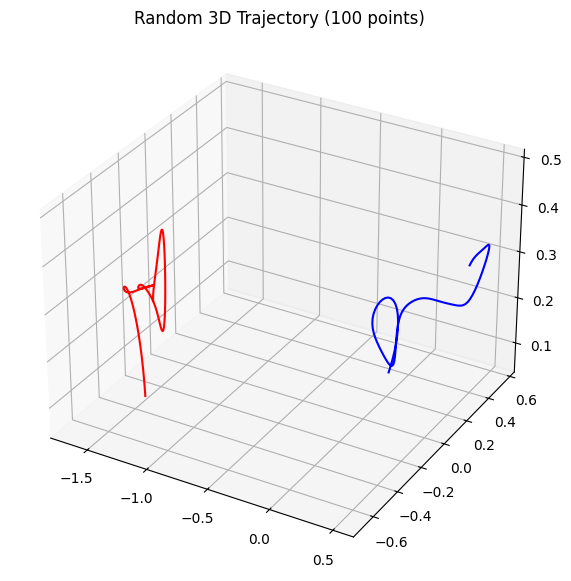

Saved to trajectory.csv
Saved to trajectory_with_noise.csv


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R
from scipy.ndimage import gaussian_filter1d
import pandas as pd

# Number of points
N = 100

# Generate small random velocity changes (Brownian-like)
np.random.seed(32)  # for reproducibility
vel = np.random.randn(N, 3) * 0.05  # small random steps

# Integrate velocities to get positions (trajectory)
pos = np.cumsum(vel, axis=0)

# Optional: smooth the trajectory slightly
pos_smooth = gaussian_filter1d(pos, sigma=5, axis=0)

# 2. Create random rotation and translation
rot = R.random(random_state=11)  # random rotation
t = np.random.randn(3)   # random translation up to ±2

print("Rotation (as quaternion):", rot.as_quat())
print("Rotation (as euler angles):", rot.as_euler("xyz") * 180 / np.pi)
print("Translation vector:", t)

# 3. Apply rotation and translation
pos_transformed = pos_smooth @ rot.as_matrix() + t

# Plot the trajectory
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot(
    pos_smooth[:, 0], pos_smooth[:, 1], pos_smooth[:, 2], c="blue", label="Trajectory 0"
)
ax.plot(
    pos_transformed[:, 0],
    pos_transformed[:, 1],
    pos_transformed[:, 2],
    c="red",
    label="Trajectory 1",
)
ax.set_title("Random 3D Trajectory (100 points)")
plt.show()

data = np.hstack([pos, pos_transformed])
columns = ['x', 'y', 'z', 'x_t', 'y_t', 'z_t']
df = pd.DataFrame(data, columns=columns)
df.to_csv('trajectory.csv', index=False)
print("Saved to trajectory.csv")